# ¿Por qué se ganan y se pierden las partidas? — EDA

**Pregunta:** ¿de qué depende ganar? ¿Mecánicas propias, el equipo, counters,
composición, builds, oro, farm, torres, objetivos?

**Pregunta previa, más importante:** ¿qué preguntas *pueden* responder estos
datos? Un EDA honesto empieza por eso.

### Las capas del warehouse (bronce / plata / oro)

Sí, es la arquitectura *medallion* con otros nombres:

| Medallion | ward-eye | Qué tiene |
|---|---|---|
| Bronce | `lol_raw` (dlt) | Datos tal cual vienen de la API, aplanados. |
| Plata | `lol_staging` (vistas) + `lol_intermediate` | Limpio y tipado, con métricas derivadas (por minuto, wards reales, snapshots @minuto). |
| Oro | `lol_marts` | Tablas listas para consumir: una fila por partida tuya, por campeón, por semana… |

Para el análisis bajamos a plata (`stg_*`, `int_*`) porque los marts solo
tienen tu fila, y acá hacen falta los 10 jugadores. Los datasets se arman en
`analysis/data.py`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

import data as d   # analysis/data.py

# Paleta: victoria = azul, derrota = naranja (validada para daltonismo)
WIN, LOSS, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#8a8984"
sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#d6d5d0", "grid.color": "#ecebe7", "axes.labelcolor": INK,
    "text.color": INK, "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
})
pd.set_option("display.precision", 3)

CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=0)

def cv_auc(X, y, model=None):
    # AUC fuera de muestra: 5-fold repetido 20 veces → media y desvío.
    model = model or make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    s = cross_val_score(model, X, y, cv=CV, scoring="roc_auc")
    return s.mean(), s.std()

## 1. Inventario: qué hay en cada tabla

In [2]:
inventory = d._q('''
    select t.table_schema as schema, t.table_name as tabla,
           case t.table_type when 'VIEW' then 'vista' else 'tabla' end as tipo,
           count(c.column_name) as columnas
    from information_schema.tables t
    join information_schema.columns c using (table_schema, table_name)
    where t.table_schema in ('lol_raw', 'lol_staging', 'lol_intermediate', 'lol_marts')
      and t.table_name not like '\\_dlt%' escape '\\'
    group by all order by 1, 2
''')
inventory["filas"] = [d._q(f"select count(*) n from {s}.{t}").n[0] for s, t in zip(inventory.schema, inventory.tabla)]
grain = {
    "raw_matches": "1 por partida", "raw_participants": "10 por partida",
    "raw_timeline_frames": "participante × minuto", "raw_timeline_events": "1 por evento",
    "raw_summoners": "1 (tu cuenta)", "raw_player_rank_snapshots": "10 por partida (desde oct-2026)",
    "stg_matches": "1 por partida (sin remakes)", "stg_participants": "10 por partida",
    "stg_timeline_frames": "participante × minuto", "stg_timeline_events": "1 por evento",
    "stg_player_rank_snapshots": "10 por partida con snapshot",
    "int_frame_snapshots": "participante × hito (5/10/15/20/25)",
    "mart_match_performance": "1 por partida tuya", "mart_champion_stats": "1 por campeón",
    "mart_player_trends": "1 por semana × cola", "mart_early_game": "1 por partida tuya",
    "mart_jungle_matchup": "1 por partida de jungla", "mart_objective_control": "1 por partida",
    "mart_match_rank_context": "1 por partida con snapshot",
}
inventory["grano"] = inventory.tabla.map(grain)
inventory

,schema,tabla,tipo,columnas,filas,grano
0,lol_intermediate,int_frame_snapshots,tabla,11,9810,participante × hito (5/10/15/20/25)
1,lol_marts,mart_champion_stats,tabla,27,8,1 por campeón
2,lol_marts,mart_early_game,tabla,17,204,1 por partida tuya
3,lol_marts,mart_jungle_matchup,tabla,18,202,1 por partida de jungla
4,lol_marts,mart_match_performance,tabla,49,204,1 por partida tuya
5,lol_marts,mart_match_rank_context,tabla,28,11,1 por partida con snapshot
6,lol_marts,mart_objective_control,tabla,16,204,1 por partida
7,lol_marts,mart_player_trends,tabla,22,20,1 por semana × cola
8,lol_raw,raw_matches,tabla,12,219,1 por partida
9,lol_raw,raw_participants,tabla,52,2190,10 por partida


## 2. Primero, la realidad muestral

Antes de buscar correlaciones conviene ver **cuánta información hay**, porque
eso define qué efectos se pueden detectar.

In [3]:
tf = d.team_frame()             # una fila por partida × minuto de corte
t15 = d.team_at(15)
mine = d.my_jungle()
games = tf.drop_duplicates("match_id")

print(f"Partidas (sin remakes): {games.match_id.nunique()}")
print(f"Winrate: {games.win.mean():.1%}")
print(f"Período: {games.game_date.min():%Y-%m-%d} → {games.game_date.max():%Y-%m-%d}")
print("Campeones tuyos:", mine.my_champion.value_counts().to_dict())

Partidas (sin remakes): 204
Winrate: 49.5%
Período: 2026-03-29 → 2026-10-25
Campeones tuyos: {'MonkeyKing': 74, 'Kindred': 64, 'Warwick': 40, 'DrMundo': 11, 'Nocturne': 7, 'XinZhao': 3, 'MasterYi': 3}


In [4]:
# ¿Cuántas partidas hacen falta para detectar una diferencia de winrate?
power = NormalIndPower()
rows = []
for delta in (0.05, 0.10, 0.15, 0.20):
    es = proportion_effectsize(0.50 + delta, 0.50)
    n = power.solve_power(effect_size=es, alpha=0.05, power=0.8)
    rows.append({"diferencia de winrate": f"50% vs {50 + delta*100:.0f}%", "partidas por grupo": int(np.ceil(n))})
pd.DataFrame(rows)

,diferencia de winrate,partidas por grupo
0,50% vs 55%,1565
1,50% vs 60%,388
2,50% vs 65%,170
3,50% vs 70%,93


**Lectura.** Con unas 200 partidas, partidas en dos grupos de ~100 solo
permiten detectar diferencias de **20 puntos** de winrate. Algo como "con este
campeón gano 5 puntos más" necesita ~1.500 partidas *por grupo*. Esto ya
descarta varias preguntas antes de empezar (ver §8).

Además el dataset es de **un solo jugador, casi siempre en jungla y con tres
campeones**. Las conclusiones son sobre *tus* partidas, no sobre el juego en
general.

## 3. Trampa #1: las stats de fin de partida no explican la victoria

Lo primero que uno haría es correlacionar KDA, oro/min, daño, etc. contra
`win`. Mirá qué pasa con los 10 jugadores de cada partida:

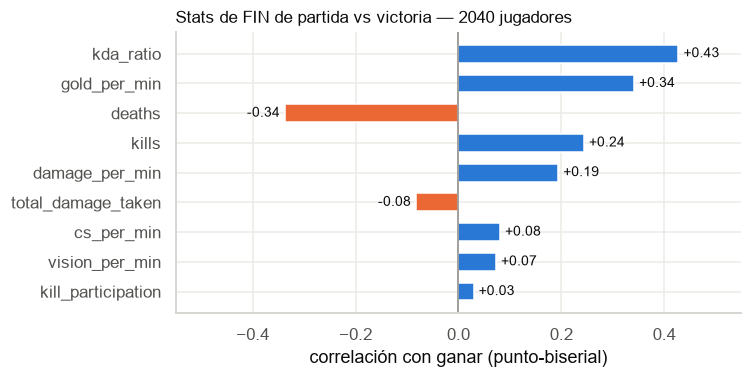

In [5]:
p = d.participants()
end_stats = ["kda_ratio", "gold_per_min", "deaths", "kills", "damage_per_min",
             "total_damage_taken", "cs_per_min", "vision_per_min", "kill_participation"]
corr_end = pd.Series({c: stats.pointbiserialr(p.win, p[c].fillna(0))[0] for c in end_stats})
corr_end = corr_end.reindex(corr_end.abs().sort_values().index)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(corr_end.index, corr_end.values, color=[WIN if v > 0 else LOSS for v in corr_end], height=0.6)
ax.axvline(0, color=MUTED, lw=1)
for i, v in enumerate(corr_end.values):
    ax.text(v + (0.01 if v > 0 else -0.01), i, f"{v:+.2f}", va="center",
            ha="left" if v > 0 else "right", fontsize=9, color=INK)
ax.set_xlabel("correlación con ganar (punto-biserial)")
ax.set_title(f"Stats de FIN de partida vs victoria — {len(p)} jugadores", loc="left", fontsize=11)
ax.set_xlim(-0.55, 0.55)
plt.tight_layout(); plt.show()

**Lectura.** KDA (+0.43), oro/min (+0.34) y muertes (−0.34) parecen "los
factores de la victoria", pero son en gran parte **consecuencia** de ganar:
el equipo que gana mata más, muere menos y junta más oro *porque* va ganando.
Es **causalidad inversa**. Un modelo que use estas variables "predice" bien
(en tus partidas, AUC ≈ 0.90 solo con tu KDA) y no sirve para nada: no dice qué hacer distinto.

**Regla para el resto del notebook:** solo se usan variables medidas **hasta
el minuto X** para explicar un resultado que ocurre después. Esa es la
diferencia entre predecir y hacer trampa (*data leakage*).

## 4. ¿Cuándo se decide una partida?

Para cada partida tomamos el **diferencial de oro de equipo** (mi equipo − el
rival) en los minutos 5, 10, 15 y 20, y medimos cuánto predice el resultado
con validación cruzada.

> **AUC**: probabilidad de que el modelo le asigne más chance de ganar a una
> partida ganada que a una perdida tomadas al azar. 0.5 = moneda, 1 = perfecto.

In [6]:
feats = ["gold_diff", "xp_diff", "cs_diff", "kills_diff", "structures_diff",
         "dragons_diff", "grubs_diff", "herald_diff",
         "first_blood_mine", "first_tower_mine", "first_dragon_mine"]
rows = []
for m in d.MINUTES:
    t = tf[tf.minute == m].fillna({c: 0 for c in feats})
    g = cv_auc(t[["gold_diff"]], t.win)
    a = cv_auc(t[feats], t.win)
    rows.append({"minuto": m, "partidas": len(t), "AUC solo oro": g[0], "± oro": g[1],
                 "AUC 11 variables": a[0], "± todas": a[1]})
auc_by_min = pd.DataFrame(rows)
auc_by_min

,minuto,partidas,AUC solo oro,± oro,AUC 11 variables,± todas
0,5,204,0.664,0.073,0.719,0.067
1,10,203,0.745,0.071,0.732,0.072
2,15,201,0.784,0.068,0.787,0.068
3,20,194,0.844,0.052,0.820,0.057


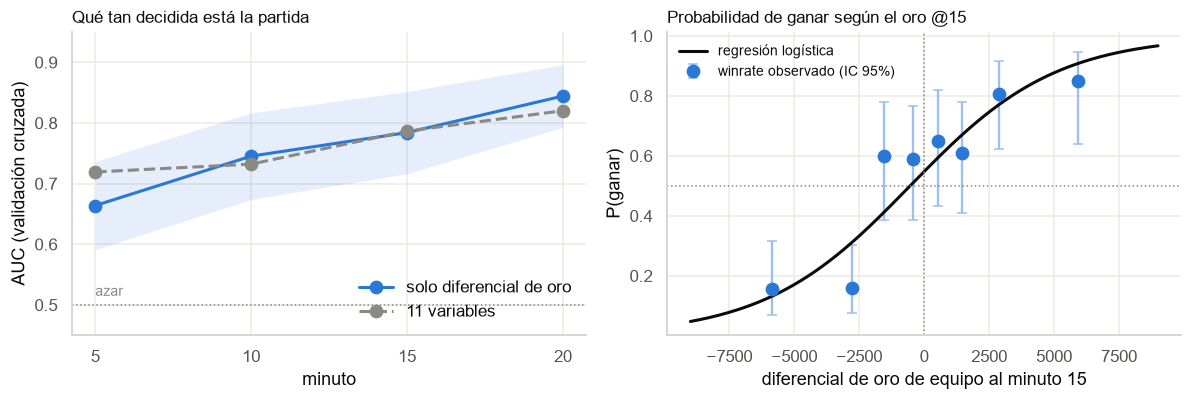

Cada +1000 de oro de equipo @15 multiplica las odds de ganar por 1.43


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

ax = axes[0]
ax.plot(auc_by_min.minuto, auc_by_min["AUC solo oro"], marker="o", ms=8, lw=2, color=WIN, label="solo diferencial de oro")
ax.fill_between(auc_by_min.minuto, auc_by_min["AUC solo oro"] - auc_by_min["± oro"],
                auc_by_min["AUC solo oro"] + auc_by_min["± oro"], color=WIN, alpha=0.12, lw=0)
ax.plot(auc_by_min.minuto, auc_by_min["AUC 11 variables"], marker="o", ms=8, lw=2, color=MUTED, ls="--", label="11 variables")
ax.axhline(0.5, color=MUTED, lw=1, ls=":")
ax.text(5, 0.515, "azar", color=MUTED, fontsize=9)
ax.set_xticks(d.MINUTES); ax.set_ylim(0.45, 0.95)
ax.set_xlabel("minuto"); ax.set_ylabel("AUC (validación cruzada)")
ax.set_title("Qué tan decidida está la partida", loc="left", fontsize=11)
ax.legend(frameon=False, loc="lower right")

ax = axes[1]
t = t15.copy()
t["bin"] = pd.cut(t.gold_diff, bins=[-12000, -4000, -2000, -1000, 0, 1000, 2000, 4000, 12000])
b = t.groupby("bin", observed=True).agg(wr=("win", "mean"), n=("win", "size"), x=("gold_diff", "mean"))
lo, hi = proportion_confint(b.wr * b.n, b.n, method="wilson")
ax.errorbar(b.x, b.wr, yerr=[b.wr - lo, hi - b.wr], fmt="o", ms=8, color=WIN, ecolor="#9cc0ec", capsize=3, label="winrate observado (IC 95%)")
fit = smf.logit("win ~ I(gold_diff/1000)", t15).fit(disp=0)
xs = np.linspace(-9000, 9000, 200)
ax.plot(xs, fit.predict(pd.DataFrame({"gold_diff": xs})), color=INK, lw=2, label="regresión logística")
ax.axhline(0.5, color=MUTED, lw=1, ls=":"); ax.axvline(0, color=MUTED, lw=1, ls=":")
ax.set_xlabel("diferencial de oro de equipo al minuto 15"); ax.set_ylabel("P(ganar)")
ax.set_title("Probabilidad de ganar según el oro @15", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

odds_k = np.exp(fit.params.iloc[1])
print(f"Cada +1000 de oro de equipo @15 multiplica las odds de ganar por {odds_k:.2f}")

**Lectura.**

- Al **minuto 5** el oro ya predice algo (AUC ≈ 0.66). Al **15** llega a
  ≈ 0.78 y al **20** a ≈ 0.84. Las partidas se deciden bastante temprano.
- **Desde el minuto 10, agregar 10 variables más no mejora nada** (al 20
  incluso empeora): con ~200 partidas, cada variable extra suma ruido. El
  diferencial de oro ya *resume* kills, torres, farm y objetivos, porque todos
  se traducen en oro. La excepción es el **minuto 5**: ahí las otras
  variables (first blood, kills) suman algo (0.72 contra 0.66), porque todavía
  no se convirtieron en oro.
- Cada +1000 de oro @15 multiplica las *odds* de ganar por ~1.4. Ojo: esto
  todavía **no es causal**. Que tu equipo vaya arriba en oro puede deberse a que
  es mejor equipo, y eso también lo haría ganar sin ese oro.

## 5. ¿Cómo se relacionan las variables entre sí?

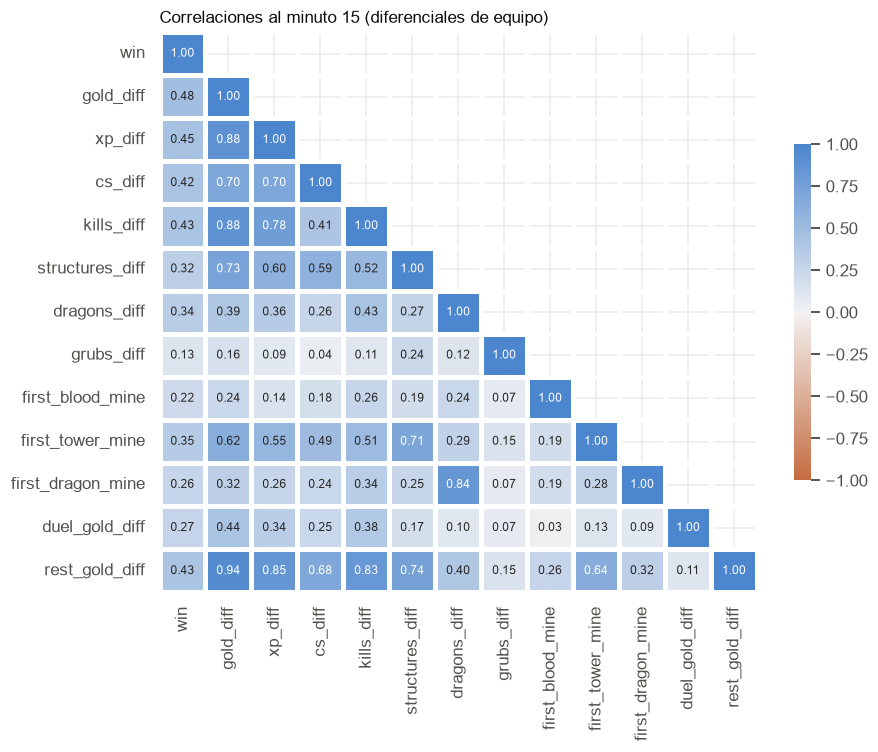

In [8]:
cols = ["win", "gold_diff", "xp_diff", "cs_diff", "kills_diff", "structures_diff",
        "dragons_diff", "grubs_diff", "first_blood_mine", "first_tower_mine", "first_dragon_mine",
        "duel_gold_diff", "rest_gold_diff"]
corr = t15[cols].fillna(0).corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
cmap = sns.diverging_palette(28, 250, s=75, l=55, center="light", as_cmap=True)
sns.heatmap(corr, mask=mask, cmap=cmap, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=2, linecolor="white", cbar_kws={"shrink": 0.6}, ax=ax)
ax.set_title("Correlaciones al minuto 15 (diferenciales de equipo)", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

**Lectura.** Oro, XP, CS y kills están **fuertemente correlacionados entre
sí** (multicolinealidad). Por eso agregarlos al modelo no suma: miden casi lo
mismo. Los objetivos tempranos (primer dragón, primera torre) correlacionan
con el oro: quien va arriba tiende a tomarlos.

¿Y un modelo de ML más potente? Gradient boosting contra regresión logística,
con las mismas variables @15:

In [9]:
X15 = t15[feats].fillna(0)
logit_auc = cv_auc(X15, t15.win)
hgb_auc = cv_auc(X15, t15.win, HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200))
pd.DataFrame({"modelo": ["Regresión logística", "Gradient boosting"],
              "AUC": [logit_auc[0], hgb_auc[0]], "±": [logit_auc[1], hgb_auc[1]]})

,modelo,AUC,±
0,Regresión logística,0.787,0.068
1,Gradient boosting,0.794,0.063


**Lectura.** Empate técnico: la diferencia queda muy dentro del desvío.
Con 200 filas, un modelo complejo no tiene de dónde aprender interacciones, y
la logística tiene la ventaja de ser interpretable. **Más ML no compensa
falta de datos.**

## 6. ¿Depende de vos o del equipo?

Partimos el diferencial de oro de equipo en dos:

- **duelo**: tu oro − el del jungla rival;
- **resto**: los otros 4 de tu equipo − los otros 4 rivales.

Por construcción `gold_diff = duel_gold_diff + rest_gold_diff`.

In [10]:
rows = []
for m in (10, 15, 20):
    t = tf[tf.minute == m]
    var = t.gold_diff.var()
    r = smf.logit("win ~ I(duel_gold_diff/1000) + I(rest_gold_diff/1000)", t).fit(disp=0)
    rows.append({
        "minuto": m,
        "% varianza: duelo": t.duel_gold_diff.var() / var,
        "% varianza: resto": t.rest_gold_diff.var() / var,
        "coef duelo (por 1000)": r.params.iloc[1], "EE duelo": r.bse.iloc[1],
        "coef resto (por 1000)": r.params.iloc[2], "EE resto": r.bse.iloc[2],
    })
split = pd.DataFrame(rows)
split

,minuto,% varianza: duelo,% varianza: resto,coef duelo (por 1000),EE duelo,coef resto (por 1000),EE resto
0,10,0.123,0.904,0.577,0.234,0.520,0.098
1,15,0.112,0.820,0.501,0.149,0.332,0.062
2,20,0.116,0.746,0.472,0.118,0.308,0.053


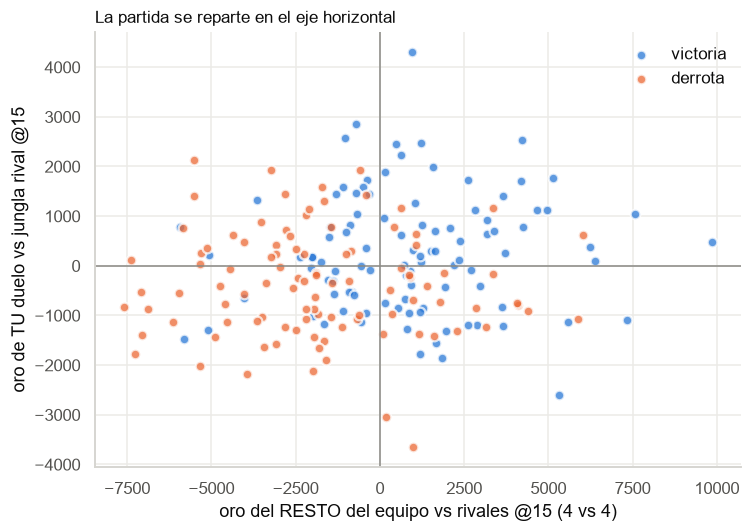

In [11]:
fig, ax = plt.subplots(figsize=(7, 5))
for w, col, lab in [(1, WIN, "victoria"), (0, LOSS, "derrota")]:
    s = t15[t15.win == w]
    ax.scatter(s.rest_gold_diff, s.duel_gold_diff, s=40, color=col, alpha=0.75,
               edgecolor="white", linewidth=1.5, label=lab)
ax.axhline(0, color=MUTED, lw=1); ax.axvline(0, color=MUTED, lw=1)
ax.set_xlabel("oro del RESTO del equipo vs rivales @15 (4 vs 4)")
ax.set_ylabel("oro de TU duelo vs jungla rival @15")
ax.set_title("La partida se reparte en el eje horizontal", loc="left", fontsize=11)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Lectura.**

- **Por cada 1000 de oro, tu duelo pesa igual o más que el del resto**: al
  minuto 10 los coeficientes son parecidos, y al 15 y al 20 el tuyo es ~1.5
  veces mayor (los errores estándar del duelo son más grandes, así que los
  intervalos se solapan). Ganarle al jungla rival importa.
- Pero **tu duelo explica solo ~11-12% de la varianza del oro de equipo**. El
  resto (4 vs 4) explica ~80%. Las partidas se mueven mucho más en el eje
  horizontal del gráfico que en el vertical.
- Traducción: tu impacto *por unidad* es alto, pero el rango de lo que movés
  en el duelo es chico comparado con lo que pasa en las otras 4 líneas. Eso
  no quiere decir que no influyas en ellas: los ganks *son* jungla
  influyendo en el "resto". Este corte mide oro, no influencia.

## 7. Tus métricas de jungla, controlando por el equipo

¿Alguna de tus métricas tempranas suma información **además** de cómo le va al
resto del equipo?

In [12]:
x = mine.merge(t15[["match_id", "rest_gold_diff"]], on="match_id").dropna()
x["rest_k"] = x.rest_gold_diff / 1000
m0 = smf.logit("win ~ rest_k", x).fit(disp=0)
m1 = smf.logit("win ~ rest_k + early_kills + deaths_pre15 + camp_diff_at_15 + my_wards_pre15", x).fit(disp=0)
summary = pd.DataFrame({"coef": m1.params, "IC 2.5%": m1.conf_int()[0], "IC 97.5%": m1.conf_int()[1],
                        "p": m1.pvalues, "odds ratio": np.exp(m1.params)}).drop("Intercept")
print(f"Pseudo-R² solo equipo: {m0.prsquared:.3f}  →  con tus métricas: {m1.prsquared:.3f}")
print(f"Test de razón de verosimilitud: p = {stats.chi2.sf(2*(m1.llf - m0.llf), m1.df_model - m0.df_model):.3f}")
summary

Pseudo-R² solo equipo: 0.155  →  con tus métricas: 0.191
Test de razón de verosimilitud: p = 0.041


,coef,IC 2.5%,IC 97.5%,p,odds ratio
rest_k,0.322,1.960e-01,0.448,5.465e-07,1.380
early_kills,0.198,2.755e-02,0.369,2.283e-02,1.219
deaths_pre15,-0.086,-3.351e-01,0.164,5.009e-01,0.918
camp_diff_at_15,0.016,-7.179e-04,0.033,6.054e-02,1.016
my_wards_pre15,0.011,-1.562e-01,0.179,8.940e-01,1.011


**Lectura.** Con el resto del equipo ya en el modelo:

- **Kills tempranas** (antes del 15) tiene un efecto positivo distinguible de
  cero: cada kill temprana sube las odds ~20%. Probablemente capta ganks que
  salen bien, que es influencia tuya sobre el resto del mapa.
- **Diferencial de campamentos** @15: positivo y en el borde de la
  significancia.
- **Muertes tempranas** y **wards** tempranas: una vez que se conoce el estado
  del equipo, no se distinguen de cero.
- En conjunto, tus métricas suman información sobre el equipo (test de razón
  de verosimilitud p ≈ 0.04), pero poca: el pseudo-R² pasa de 0.155 a 0.191.

Son asociaciones con muestra chica, no un manual de juego. Pero apuntan a algo
accionable: *convertir el tempo en kills* pesa más que farmear o wardear
solo.

## 8. Objetivos: ¿el primer dragón *causa* la victoria?

Acá está el corazón de la pregunta causal. Ingenuamente:

In [13]:
fd = d.gold_diff_before().merge(t15[["match_id", "win", "first_dragon_mine"]], on="match_id")
fd["g_k"] = fd.gold_diff_before_dragon / 1000
naive = smf.logit("win ~ first_dragon_mine", fd).fit(disp=0)
adj = smf.logit("win ~ first_dragon_mine + g_k", fd).fit(disp=0)
who = smf.logit("first_dragon_mine ~ g_k", fd).fit(disp=0)
pd.DataFrame({
    "modelo": ["ingenuo: win ~ dragón", "ajustado: win ~ dragón + oro previo", "¿quién toma el dragón?: dragón ~ oro previo"],
    "coef dragón (log-odds)": [naive.params["first_dragon_mine"], adj.params["first_dragon_mine"], np.nan],
    "odds ratio dragón": [np.exp(naive.params["first_dragon_mine"]), np.exp(adj.params["first_dragon_mine"]), np.nan],
    "p": [naive.pvalues["first_dragon_mine"], adj.pvalues["first_dragon_mine"], who.pvalues["g_k"]],
})

,modelo,coef dragón (log-odds),odds ratio dragón,p
0,ingenuo: win ~ dragón,1.089,2.971,2.096e-04
1,ajustado: win ~ dragón + oro previo,0.687,1.987,3.176e-02
2,¿quién toma el dragón?: dragón ~ oro previo,NaN,NaN,5.906e-07


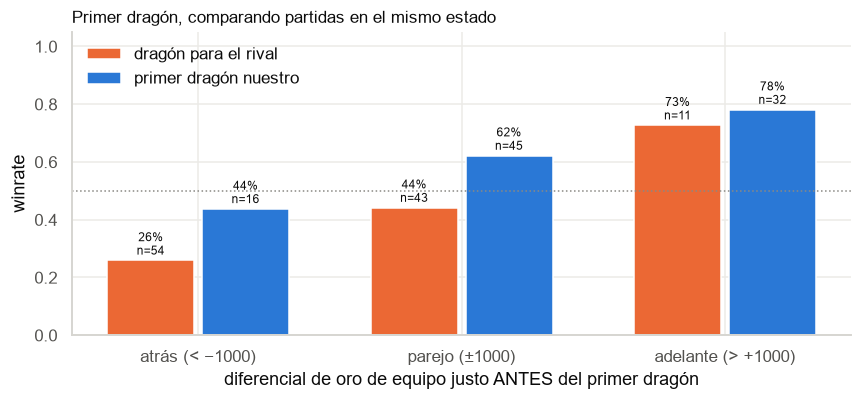

In [14]:
fd["estado"] = pd.cut(fd.gold_diff_before_dragon, [-1e9, -1000, 1000, 1e9],
                      labels=["atrás (< −1000)", "parejo (±1000)", "adelante (> +1000)"])
st = fd.groupby(["estado", "first_dragon_mine"], observed=True).win.agg(["mean", "size"]).reset_index()

fig, ax = plt.subplots(figsize=(8, 3.8))
w = 0.36
xs = np.arange(3)
for k, (val, col, lab) in enumerate([(0, LOSS, "dragón para el rival"), (1, WIN, "primer dragón nuestro")]):
    s = st[st.first_dragon_mine == val].set_index("estado").reindex(fd.estado.cat.categories)
    bars = ax.bar(xs + (k - 0.5) * w, s["mean"], width=w - 0.03, color=col, label=lab)
    for xi, (mval, n) in zip(xs + (k - 0.5) * w, zip(s["mean"], s["size"])):
        ax.text(xi, mval + 0.02, f"{mval:.0%}\nn={n}", ha="center", fontsize=8, color=INK)
ax.set_xticks(xs, fd.estado.cat.categories)
ax.set_ylim(0, 1.05); ax.set_ylabel("winrate")
ax.axhline(0.5, color=MUTED, lw=1, ls=":")
ax.set_xlabel("diferencial de oro de equipo justo ANTES del primer dragón")
ax.set_title("Primer dragón, comparando partidas en el mismo estado", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

**Lectura — razonamiento causal en tres pasos.**

1. **Ingenuo**: tomar el primer dragón se asocia a ~3× las odds de ganar.
2. **Confusor**: el equipo que va arriba en oro *tiende a tomar* el dragón
   (p ≈ 0) y *tiende a ganar* de todos modos. El oro previo causa las dos
   cosas, así que parte de la asociación es espuria:

   ```
   oro previo ──► primer dragón ──► victoria
        └───────────────────────────────▲
   ```
3. **Ajustado** por el oro *justo antes* del dragón, el efecto baja a ~2×. Se
   ve en el gráfico: dentro de cada estado (atrás, parejo, adelante), tomar el
   dragón sigue sumando, pero menos de lo que sugería la versión ingenua.

¿Es causal ese 2×? **Todavía no del todo.** Quedan confusores sin medir (la
calidad del equipo, una pelea ganada que dio el dragón *y* la ventaja) y la
muestra es chica (los IC son anchos). Lo correcto es decir que *hay evidencia
consistente con un efecto propio del dragón, más chico que la asociación
cruda*. Con datos observacionales de 200 partidas, no se puede afirmar más.

## 9. Lo que estos datos NO pueden responder (todavía)

In [15]:
pairs = mine.groupby(["my_champion", "enemy_champion"]).size()
champ_rows = []
for ch, g in mine.groupby("my_champion"):
    if len(g) >= 10:
        lo, hi = proportion_confint(g.win.sum(), len(g), method="wilson")
        champ_rows.append({"campeón": ch, "partidas": len(g), "winrate": g.win.mean(), "IC 95% bajo": lo, "IC 95% alto": hi})
print(f"Junglas rivales distintos: {mine.enemy_champion.nunique()}")
print(f"Matchups (tu campeón × rival) distintos: {len(pairs)}; con ≥5 partidas: {(pairs >= 5).sum()}; máximo: {pairs.max()}")
print(f"Campeones distintos en tus lobbies: {p.champion_name.nunique()}")
pd.DataFrame(champ_rows)

Junglas rivales distintos: 55
Matchups (tu campeón × rival) distintos: 110; con ≥5 partidas: 6; máximo: 10
Campeones distintos en tus lobbies: 167


,campeón,partidas,winrate,IC 95% bajo,IC 95% alto
0,DrMundo,11,0.545,0.280,0.787
1,Kindred,64,0.516,0.396,0.634
2,MonkeyKing,74,0.554,0.441,0.662
3,Warwick,40,0.425,0.285,0.578


In [16]:
# Composición: clases de Data Dragon (Tank, Fighter, Mage, …), mi equipo − rival
tags = d.champion_tags()
pc = p.assign(champion_lower=p.champion_name.str.lower()).merge(tags.drop(columns="champion_name"), on="champion_lower", how="left")
my_team = pc[pc.is_me][["match_id", "team_id"]].rename(columns={"team_id": "my_team"})
pc = pc.merge(my_team, on="match_id")
pc["sign"] = np.where(pc.team_id == pc.my_team, 1, -1)
classes = ["Tank", "Fighter", "Mage", "Assassin", "Marksman", "Support"]
for c in classes:
    pc[c] = pc.tags.apply(lambda ts: c in ts) * pc.sign
comp = pc.groupby("match_id")[classes].sum().add_suffix("_diff").join(
    pc[pc.is_me].set_index("match_id").win)
comp_corr = pd.DataFrame([{"variable": c, "r": stats.pointbiserialr(comp.win, comp[c])[0],
                           "p": stats.pointbiserialr(comp.win, comp[c])[1]} for c in comp.columns if c != "win"])
print(f"AUC composición (6 variables): {cv_auc(comp.drop(columns='win'), comp.win)[0]:.3f}")
comp_corr

AUC composición (6 variables): 0.482


,variable,r,p
0,Tank_diff,0.095,0.178
1,Fighter_diff,-0.049,0.486
2,Mage_diff,-0.025,0.723
3,Assassin_diff,-0.051,0.470
4,Marksman_diff,-0.003,0.967
5,Support_diff,0.074,0.293


**Lectura.**

- **Counters**: 110 matchups distintos de jungla en 202 partidas, y solo 6
  con 5 partidas o más. Estimar un counter así es imposible: harían falta
  cientos de partidas *por matchup*.
- **Tus campeones**: Wukong 55%, Kindred 52%, Warwick 42%, pero todos los
  intervalos de confianza **cruzan el 50%**. No hay evidencia de que uno sea
  mejor que otro para vos. Puede haberla, pero estos datos no alcanzan para
  verla.
- **Composición** (clases de campeón): ninguna correlación significativa y AUC
  ≈ 0.48, igual que una moneda. Con 167 campeones distintos en los lobbies, la
  composición es casi única en cada partida.
- **Builds**: `items_json` son los ítems *finales*, que dependen de cuánto oro
  juntaste (fuga del resultado otra vez) y son demasiado variados para 200
  partidas. Para analizar builds en serio haría falta el orden de compra (está
  en `ITEM_PURCHASED` del timeline) y muchísimas más partidas.

## 10. Trampa #2: encontrar patrones en el ruido

Es tentador mirar winrate por hora del día, por partida de la sesión, después
de una derrota…

In [17]:
mp = d._q("select win::int as win, game_start_at from lol_marts.mart_match_performance order by game_start_at")
mp["hora"] = pd.cut(mp.game_start_at.dt.hour, [-1, 11, 17, 21, 24], labels=["madrugada/mañana", "tarde", "noche", "trasnoche"])
by_hour = mp.groupby("hora", observed=True).win.agg(["mean", "size"])
chi_p = stats.chi2_contingency(pd.crosstab(mp.hora, mp.win))[1]
print(f"Chi² hora × resultado: p = {chi_p:.2f}")

gap_h = mp.game_start_at.diff().dt.total_seconds() / 3600
mp["sesion"] = (gap_h.isna() | (gap_h > 2)).cumsum()
mp["n_en_sesion"] = mp.groupby("sesion").cumcount() + 1
idx_fit = smf.logit("win ~ n_en_sesion", mp).fit(disp=0)
print(f"Efecto de 'número de partida en la sesión': p = {idx_fit.pvalues['n_en_sesion']:.2f}")
by_hour

Chi² hora × resultado: p = 0.28
Efecto de 'número de partida en la sesión': p = 0.63


,mean,size
hora,,
madrugada/mañana,0.367,30
tarde,0.538,78
noche,0.536,69
trasnoche,0.407,27


**Lectura.** De tarde y de noche el winrate es 54%; a la mañana, 37%. La
diferencia *parece* grande, pero el test da p ≈ 0.3: es perfectamente
compatible con el azar. Lo mismo pasa con jugar varias partidas seguidas.

Si probás 20 cortes distintos, en promedio **uno va a salir "significativo"
con p < 0.05 por pura casualidad** (comparaciones múltiples). La defensa es
plantear la hipótesis *antes* de mirar los datos, y desconfiar de los
hallazgos que no se buscaban.

## 11. Conclusiones

### Lo que sí se puede afirmar (con estos datos)

1. **Las partidas se deciden temprano.** El diferencial de oro de equipo al
   minuto 15 predice el resultado con AUC ≈ 0.78, y al 20 con ≈ 0.84.
2. **El oro resume casi todo.** Kills, torres, farm y objetivos tempranos no
   agregan capacidad predictiva una vez que se conoce el oro. Un modelo de ML
   más complejo tampoco.
3. **Tu duelo vale, por unidad, tanto como el del resto, pero mueve poco.**
   Explica ~11-12% de la varianza del oro de equipo; las otras 4 líneas,
   entre 75 y 90%.
4. **Lo que más suma de tu juego temprano son las kills** (ganks y peleas
   ganadas antes del 15), incluso controlando por el estado del equipo.
5. **El primer dragón se asocia a ganar más de lo que causa.** Las odds
   pasan de ~3× a ~2× al ajustar por el oro previo: más de un tercio del
   efecto aparente (en log-odds) se explica porque lo toma el equipo que ya
   iba ganando.

### Lo que no se puede afirmar

Counters, composición, builds, "mi mejor campeón", la hora del día: **la
muestra no alcanza**. No es que no importen; es que 200 partidas de un solo
jugador no tienen poder estadístico para verlo.

### ¿Cómo sacarle valor real a estos datos?

- **Escalar los datos, no el modelo.** La Riot API devuelve el historial de
  *cualquier* jugador. Bajando las partidas de los otros 9 jugadores de cada
  lobby (mismo elo y servidor), el dataset pasa de 200 partidas a decenas de
  miles en pocas semanas. Con eso counters, composición y builds se vuelven
  estimables. Es un cambio acotado en dlt: otro recurso con otra lista de
  `match_id`.
- **Experimentar sobre vos mismo.** La forma más limpia de tener causalidad
  con un solo jugador es intervenir. Por ejemplo: "las próximas 40 partidas
  priorizo un gank antes del minuto 6", fijando la regla antes de jugar. Con
  la métrica decidida de antemano, comparar contra tu línea base es mucho más
  creíble que cualquier correlación.
- **Usar el estado @15 como métrica de proceso.** Como el oro @15 predice
  bien y está *más cerca de tus decisiones* que el win/loss, es una métrica
  de mejora con mucho menos ruido que el winrate.